# ENGE707 Kaggle Competition: Final Full-Data ResNet18

## Final Training and Submission Pipeline

This notebook trains the final ResNet18 on **all 63,660 labelled images**. Its settings are based on the completed baseline, group-aware split, TTA, and geometry experiments.

Evidence-supported decisions:

- retain black square padding and 224 × 224 input;
- retain ImageNet normalization and the original training augmentation;
- retain ImageNet-pretrained ResNet18 and discriminative learning rates;
- use two classifier-only epochs followed by eight full fine-tuning epochs;
- do not use alternative padding, direct resizing, centre cropping, or flip TTA; and
- preserve sample-submission row order exactly.

No validation subset is used. The ten-epoch schedule was selected before this run from two completed validation experiments, so Kaggle test data is never used for model selection.

## 1. Import the Required Libraries

Only libraries required for data loading, training, plotting, prediction, and result packaging are imported.

In [14]:
# Imports the libraries used for full data training and prediction
from pathlib import Path
from contextlib import nullcontext
from itertools import chain
from zipfile import ZipFile, ZIP_DEFLATED
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from torchvision.transforms import InterpolationMode

from IPython.display import FileLink, Markdown, display

## 2. Configure the Final Experiment

Training follows the same ten-epoch schedule used in the validated ResNet18 experiments. The notebook can resume from an attached recovery checkpoint. For the final continuation, the optional time guard is disabled so Kaggle can run every remaining epoch without a voluntary pause.

In [15]:
# Sets the full data training schedule and safety switches
RUN_TRAINING = True
RANDOM_SEED = 42

HEAD_ONLY_EPOCHS = 2
FINE_TUNING_EPOCHS = 8
TOTAL_EPOCHS = HEAD_ONLY_EPOCHS + FINE_TUNING_EPOCHS

HEAD_ONLY_LEARNING_RATE = 1e-3
EARLY_BACKBONE_LEARNING_RATE = 1e-5
FINAL_BLOCK_LEARNING_RATE = 5e-5
CLASSIFIER_LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

KAGGLE_BATCH_SIZE = 128
USE_TRAINING_TIME_GUARD = False
TRAINING_TIME_GUARD_MINUTES = 105
NEXT_EPOCH_ALLOWANCE_MINUTES = 15
ASSIGNMENT_TIME_LIMIT_MINUTES = 120

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Training enabled:", RUN_TRAINING)
print("Final schedule:", TOTAL_EPOCHS, "epochs")
print("Random seed:", RANDOM_SEED)
print("Time guard enabled:", USE_TRAINING_TIME_GUARD)
print("Time guard threshold:", TRAINING_TIME_GUARD_MINUTES, "minutes")
print("Next-epoch allowance:", NEXT_EPOCH_ALLOWANCE_MINUTES, "minutes")

Training enabled: True
Final schedule: 10 epochs
Random seed: 42
Time guard enabled: False
Time guard threshold: 105 minutes
Next-epoch allowance: 15 minutes


## 3. Locate Competition Data and Saved Configuration

On Kaggle, attach the private competition dataset and `facial-feature-project-artifacts`. The artifact dataset supplies `preprocessing_config.json`, the official ImageNet ResNet18 weights, and—when continuing a stopped run—the latest checkpoint and history CSV. Input files remain read-only.

In [16]:
# Finds competition images labels and the saved preprocessing settings
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_kaggle_file(filename, required=True, preferred_text=None):
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if preferred_text:
        preferred = [
            path for path in matches
            if preferred_text.lower() in str(path).lower()
        ]
        if preferred:
            matches = preferred
    if len(matches) == 1:
        return matches[0]
    if not required and len(matches) == 0:
        return None
    raise RuntimeError(
        f"Expected one {filename}, found {len(matches)}:\n"
        + "\n".join(str(path) for path in matches)
    )


def find_image_directory(filename, split_name):
    matches = sorted(Path("/kaggle/input").rglob(filename))
    matches = [
        path for path in matches
        if split_name.lower() in {
            part.lower() for part in path.parent.parts
        }
    ]
    directories = sorted({path.parent for path in matches})
    if len(directories) != 1:
        raise RuntimeError(
            f"Expected one {split_name} image directory, found "
            f"{len(directories)}:\n"
            + "\n".join(str(path) for path in directories)
        )
    return directories[0]


if RUNNING_ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")
    TRAIN_LABELS_PATH = find_kaggle_file(
        "train_labels.csv",
        preferred_text="competition-data",
    )
    SAMPLE_SUBMISSION_PATH = find_kaggle_file(
        "sample_submission.csv",
        preferred_text="competition-data",
    )
    PREPROCESSING_CONFIG_PATH = find_kaggle_file(
        "preprocessing_config.json",
        preferred_text="facial-feature-project-artifacts",
    )
    RESUME_CHECKPOINT_INPUT_PATH = find_kaggle_file(
        "resnet18_full_data_latest.pth",
        required=False,
        preferred_text="facial-feature-project-artifacts",
    )
    RESUME_HISTORY_INPUT_PATH = find_kaggle_file(
        "full_data_training_history.csv",
        required=False,
        preferred_text="facial-feature-project-artifacts",
    )

    train_probe = (
        pd.read_csv(TRAIN_LABELS_PATH, dtype={"image_id": "string"})
        .iloc[0]["image_id"]
        .zfill(5)
        + ".jpg"
    )
    sample_probe = (
        pd.read_csv(
            SAMPLE_SUBMISSION_PATH,
            dtype={"image_id": "string"},
        ).iloc[0]["image_id"].zfill(5)
        + ".jpg"
    )
    TRAIN_IMAGE_DIR = find_image_directory(train_probe, "train")
    TEST_IMAGE_DIR = find_image_directory(sample_probe, "test")
else:
    possible_roots = [Path.cwd(), Path.cwd().parent]
    PROJECT_ROOT = next(
        (
            folder for folder in possible_roots
            if (folder / "data" / "train_labels.csv").exists()
        ),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("The project root could not be found.")
    TRAIN_LABELS_PATH = PROJECT_ROOT / "data" / "train_labels.csv"
    SAMPLE_SUBMISSION_PATH = PROJECT_ROOT / "data" / "sample_submission.csv"
    PREPROCESSING_CONFIG_PATH = (
        PROJECT_ROOT / "outputs" / "preprocessing" / "preprocessing_config.json"
    )
    RESUME_CHECKPOINT_INPUT_PATH = (
        PROJECT_ROOT / "models" / "final_full_data"
        / "resnet18_full_data_latest.pth"
    )
    RESUME_HISTORY_INPUT_PATH = (
        PROJECT_ROOT / "outputs" / "models" / "final_full_data"
        / "full_data_training_history.csv"
    )
    if not RESUME_CHECKPOINT_INPUT_PATH.exists():
        RESUME_CHECKPOINT_INPUT_PATH = None
    if not RESUME_HISTORY_INPUT_PATH.exists():
        RESUME_HISTORY_INPUT_PATH = None
    TRAIN_IMAGE_DIR = PROJECT_ROOT / "data" / "train" / "train"
    TEST_IMAGE_DIR = PROJECT_ROOT / "data" / "test" / "test"

MODEL_DIR = PROJECT_ROOT / "models" / "final_full_data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "models" / "final_full_data"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

LATEST_CHECKPOINT_PATH = MODEL_DIR / "resnet18_full_data_latest.pth"
FINAL_CHECKPOINT_PATH = MODEL_DIR / "resnet18_full_data_final.pth"
HISTORY_PATH = OUTPUT_DIR / "full_data_training_history.csv"
SUMMARY_PATH = OUTPUT_DIR / "full_data_training_summary.json"
CONFIG_PATH = OUTPUT_DIR / "full_data_pipeline_config.json"
CHECKS_PATH = OUTPUT_DIR / "full_data_pipeline_checks.csv"
PREDICTIONS_PATH = OUTPUT_DIR / "full_data_test_predictions.csv"
SUBMISSION_PATH = PROJECT_ROOT / "submission_resnet18_full_data.csv"
CURVES_PATH = FIGURE_DIR / "figure_32_full_data_training_curves.png"
PREDICTION_DISTRIBUTION_PATH = (
    FIGURE_DIR / "figure_33_full_data_prediction_distribution.png"
)

print("Environment:", "Kaggle" if RUNNING_ON_KAGGLE else "Local")
print("Training labels:", TRAIN_LABELS_PATH)
print("Training images:", TRAIN_IMAGE_DIR)
print("Test images:", TEST_IMAGE_DIR)
print("Resume checkpoint:", RESUME_CHECKPOINT_INPUT_PATH)
print("Resume history:", RESUME_HISTORY_INPUT_PATH)

Environment: Kaggle
Training labels: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train_labels.csv
Training images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train/train
Test images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/test/test
Resume checkpoint: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/resnet18_full_data_latest.pth
Resume history: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/full_data_training_history.csv


## 4. Load and Verify All Labels

All labelled rows are used for training. Test rows are loaded only to preserve submission order after training.

In [17]:
# Checks all training labels and records the final run configuration
with open(PREPROCESSING_CONFIG_PATH) as config_file:
    preprocessing_config = json.load(config_file)

training_table = pd.read_csv(
    TRAIN_LABELS_PATH,
    dtype={"image_id": "string", "class": "string"},
)
sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": "string", "class": "string"},
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
NUMBER_OF_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = list(preprocessing_config["normalisation_mean"])
IMAGENET_STD = list(preprocessing_config["normalisation_std"])

training_table["filename"] = (
    training_table["image_id"].str.zfill(5) + ".jpg"
)
training_table["label_index"] = training_table["class"].map(CLASS_TO_INDEX)
sample_submission["filename"] = (
    sample_submission["image_id"].str.zfill(5) + ".jpg"
)

label_mapping_valid = training_table["label_index"].notna().all()
training_files_complete = all(
    (TRAIN_IMAGE_DIR / filename).exists()
    for filename in training_table["filename"]
)
test_files_complete = all(
    (TEST_IMAGE_DIR / filename).exists()
    for filename in sample_submission["filename"]
)

data_checks = pd.DataFrame(
    {
        "check": [
            "All 63,660 labelled images are included",
            "All 29,443 test rows are included",
            "Eight official classes are configured",
            "Every label maps to an official index",
            "Every training image exists",
            "Every test image exists",
            "Training image IDs are unique",
            "Submission image IDs are unique",
        ],
        "result": [
            len(training_table) == 63660,
            len(sample_submission) == 29443,
            NUMBER_OF_CLASSES == 8,
            label_mapping_valid,
            training_files_complete,
            test_files_complete,
            training_table["image_id"].is_unique,
            sample_submission["image_id"].is_unique,
        ],
        "expected": [True] * 8,
    }
)
display(data_checks)
assert data_checks["result"].all()
print("All full-data and submission checks passed.")

,check,result,expected
0,"All 63,660 labelled images are included",True,True
1,"All 29,443 test rows are included",True,True
2,Eight official classes are configured,True,True
3,Every label maps to an official index,True,True
4,Every training image exists,True,True
5,Every test image exists,True,True
6,Training image IDs are unique,True,True
7,Submission image IDs are unique,True,True


All full-data and submission checks passed.


## 5. Recreate the Evidence-Supported Transforms

Training images receive the original moderate augmentation. Test images receive only black square padding, resizing, tensor conversion, and ImageNet normalization.

In [18]:
# Defines the training changes and fixed test preprocessing
class SquarePad:
    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        side = max(width, height)
        horizontal = side - width
        vertical = side - height
        left = horizontal // 2
        right = horizontal - left
        top = vertical // 2
        bottom = vertical - top
        return ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill=self.fill,
        )


augmentation = preprocessing_config["training_augmentation"]
training_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.RandomHorizontalFlip(
            p=augmentation["horizontal_flip_probability"]
        ),
        transforms.RandomRotation(
            degrees=augmentation["maximum_rotation_degrees"],
            interpolation=InterpolationMode.BILINEAR,
            fill=(0, 0, 0),
        ),
        transforms.ColorJitter(
            brightness=augmentation["brightness_change"],
            contrast=augmentation["contrast_change"],
            saturation=augmentation["saturation_change"],
        ),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)
test_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

assert "Random" not in repr(test_transform)
print("Training transform:\n", training_transform)
print("\nTest transform:\n", test_transform)

Training transform:
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=(0, 0, 0))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Test transform:
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 6. Create Full-Data and Test Loaders

The training loader shuffles all labelled images. The test loader never shuffles, which preserves `sample_submission.csv` order.

In [19]:
# Creates loaders for all labelled images and the unlabelled test images
class FacialFeatureDataset(Dataset):
    def __init__(self, table, image_directory, transform, labelled):
        self.table = table.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform
        self.labelled = labelled

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.image_directory / row["filename"]) as image:
            image = self.transform(image.convert("RGB"))
        item = {
            "image": image,
            "image_id": str(row["image_id"]),
            "row_index": index,
        }
        if self.labelled:
            item["label"] = int(row["label_index"])
        return item


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = KAGGLE_BATCH_SIZE if DEVICE.type == "cuda" else 32
NUM_WORKERS = 2 if RUNNING_ON_KAGGLE else 0
PIN_MEMORY = DEVICE.type == "cuda"
USE_MIXED_PRECISION = DEVICE.type == "cuda"

training_dataset = FacialFeatureDataset(
    training_table, TRAIN_IMAGE_DIR, training_transform, labelled=True
)
test_dataset = FacialFeatureDataset(
    sample_submission, TEST_IMAGE_DIR, test_transform, labelled=False
)

loader_options = {}
if NUM_WORKERS > 0:
    loader_options = {"persistent_workers": True, "prefetch_factor": 2}

loader_generator = torch.Generator().manual_seed(RANDOM_SEED)
training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=loader_generator,
    **loader_options,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_options,
)

print("Device:", DEVICE)
print("CUDA devices:", torch.cuda.device_count())
print("Training batches:", len(training_loader))
print("Test batches:", len(test_loader))

Device: cuda
CUDA devices: 2
Training batches: 498
Test batches: 231


## 7. Build the ImageNet-Pretrained ResNet18

The eight-output classifier starts from the official ImageNet weights for a new run. When a recovery checkpoint is attached, its learned weights replace that initialization so training continues from the saved epoch.

In [20]:
# Builds ResNet18 with ImageNet weights and an eight class output layer
def build_resnet18(load_pretrained):
    weight_source = "not loaded - preparation mode"
    if load_pretrained:
        weights = ResNet18_Weights.DEFAULT
        weight_filename = Path(weights.url).name
        attached_path = (
            find_kaggle_file(weight_filename, required=False)
            if RUNNING_ON_KAGGLE
            else None
        )
        cache_path = Path(torch.hub.get_dir()) / "checkpoints" / weight_filename
        if attached_path is not None:
            model = models.resnet18(weights=None)
            # Copies the saved weights into the matching model architecture
            model.load_state_dict(
                torch.load(attached_path, map_location="cpu", weights_only=True)
            )
            weight_source = f"attached Kaggle input: {attached_path}"
        elif cache_path.exists():
            model = models.resnet18(weights=None)
            # Copies the saved weights into the matching model architecture
            model.load_state_dict(
                torch.load(cache_path, map_location="cpu", weights_only=True)
            )
            weight_source = f"PyTorch cache: {cache_path}"
        else:
            try:
                model = models.resnet18(weights=weights)
                weight_source = "downloaded torchvision ImageNet weights"
            except Exception as error:
                raise RuntimeError(
                    "Attach resnet18-f37072fd.pth or enable Internet."
                ) from error
    else:
        model = models.resnet18(weights=None)

    model.fc = nn.Linear(model.fc.in_features, NUMBER_OF_CLASSES)
    return model, weight_source


resnet18_model, PRETRAINED_WEIGHT_SOURCE = build_resnet18(RUN_TRAINING)
RESUME_CHECKPOINT = None
START_EPOCH = 0

if RUN_TRAINING and RESUME_CHECKPOINT_INPUT_PATH is not None:
    if RESUME_HISTORY_INPUT_PATH is None:
        raise FileNotFoundError(
            "A resume checkpoint was found without its training history."
        )
    # Reads the saved checkpoint so training does not need to be repeated
    RESUME_CHECKPOINT = torch.load(
        RESUME_CHECKPOINT_INPUT_PATH,
        map_location="cpu",
        weights_only=False,
    )
    START_EPOCH = int(RESUME_CHECKPOINT["epoch"])
    if RESUME_CHECKPOINT.get("experiment") != "final_resnet18_full_data":
        raise RuntimeError("The attached checkpoint is from another experiment.")
    if not 1 <= START_EPOCH <= TOTAL_EPOCHS:
        raise RuntimeError("The resume epoch is outside the ten-epoch schedule.")
    if RESUME_CHECKPOINT.get("training_images") != 63660:
        raise RuntimeError("The checkpoint was not trained on all 63,660 images.")
    if RESUME_CHECKPOINT.get("class_names") != CLASS_NAMES:
        raise RuntimeError("The checkpoint class order is incorrect.")
    if RESUME_CHECKPOINT.get("class_to_index") != CLASS_TO_INDEX:
        raise RuntimeError("The checkpoint class mapping is incorrect.")
    if RESUME_CHECKPOINT.get("image_size") != IMAGE_SIZE:
        raise RuntimeError("The checkpoint image size is incorrect.")

    # Copies the saved weights into the matching model architecture
    resnet18_model.load_state_dict(
        {
            key.removeprefix("module."): value
            for key, value in RESUME_CHECKPOINT["model_state_dict"].items()
        }
    )
    PRETRAINED_WEIGHT_SOURCE = (
        f"resumed checkpoint: {RESUME_CHECKPOINT_INPUT_PATH}"
    )
elif RUN_TRAINING and RESUME_HISTORY_INPUT_PATH is not None:
    raise FileNotFoundError(
        "A resume history was found without its model checkpoint."
    )

print("Weight source:", PRETRAINED_WEIGHT_SOURCE)
print("Starting after epoch:", START_EPOCH)
print("Classifier:", resnet18_model.fc)

Weight source: resumed checkpoint: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/resnet18_full_data_latest.pth
Starting after epoch: 1
Classifier: Linear(in_features=512, out_features=8, bias=True)


## 8. Verify the Forward Pipeline and Save Configuration

A preparation pass confirms that one full-data batch produces eight output scores before any weight update occurs.

In [21]:
# Checks one forward pass and saves the pipeline configuration
example_batch = next(iter(training_loader))
# Switches the model to evaluation behaviour for prediction
resnet18_model.eval()
# Disables gradient tracking because this step does not train the model
with torch.inference_mode():
    example_logits = resnet18_model(example_batch["image"])

pretraining_checks = pd.DataFrame(
    {
        "check": [
            "All labelled images are used",
            "Input contains three colour channels",
            "Images are 224 by 224",
            "Model returns eight class scores",
            "Test loader preserves sample order",
            "Test transform has no random augmentation",
        ],
        "result": [
            len(training_dataset) == 63660,
            example_batch["image"].shape[1] == 3,
            tuple(example_batch["image"].shape[-2:]) == (224, 224),
            example_logits.shape[1] == 8,
            list(test_loader.sampler) == list(range(len(test_dataset))),
            "Random" not in repr(test_transform),
        ],
        "expected": [True] * 6,
    }
)
display(pretraining_checks)
assert pretraining_checks["result"].all()

pipeline_config = {
    "experiment": "final_resnet18_full_data",
    "training_images": len(training_dataset),
    "test_images": len(test_dataset),
    "validation_images": 0,
    "test_images_used_for_model_selection": False,
    "resume_from_epoch": START_EPOCH,
    "resume_checkpoint": (
        str(RESUME_CHECKPOINT_INPUT_PATH)
        if RESUME_CHECKPOINT_INPUT_PATH is not None
        else None
    ),
    "resume_optimizer_state_available": bool(
        RESUME_CHECKPOINT is not None
        and RESUME_CHECKPOINT.get("optimizer_state_dict") is not None
    ),
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "image_size": IMAGE_SIZE,
    "padding": "black square padding",
    "normalisation_mean": IMAGENET_MEAN,
    "normalisation_std": IMAGENET_STD,
    "training_augmentation": augmentation,
    "batch_size": BATCH_SIZE,
    "time_guard_enabled": USE_TRAINING_TIME_GUARD,
    "time_guard_minutes": TRAINING_TIME_GUARD_MINUTES,
    "head_only_epochs": HEAD_ONLY_EPOCHS,
    "fine_tuning_epochs": FINE_TUNING_EPOCHS,
    "learning_rates": {
        "head_only": HEAD_ONLY_LEARNING_RATE,
        "early_backbone": EARLY_BACKBONE_LEARNING_RATE,
        "final_block": FINAL_BLOCK_LEARNING_RATE,
        "classifier": CLASSIFIER_LEARNING_RATE,
    },
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "schedule_evidence": (
        "Original validation peaked at epoch 10; group-aware validation "
        "peaked at epoch 9 and remained within 0.04 percentage points "
        "at epoch 10."
    ),
}
with open(CONFIG_PATH, "w") as config_file:
    json.dump(pipeline_config, config_file, indent=4)
print("Pipeline configuration:", CONFIG_PATH)

,check,result,expected
0,All labelled images are used,True,True
1,Input contains three colour channels,True,True
2,Images are 224 by 224,True,True
3,Model returns eight class scores,True,True
4,Test loader preserves sample order,True,True
5,Test transform has no random augmentation,True,True


Pipeline configuration: /kaggle/working/outputs/models/final_full_data/full_data_pipeline_config.json


# Part B: Full-Data Training

The fixed schedule replaces validation-based early stopping and scheduling. This avoids using Kaggle test data to make training decisions.

## 9. Define Stage Configuration and Mixed-Precision Training

In [22]:
# Defines which layers learn during each training stage
def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def configure_stage(model, stage):
    base_model = unwrap_model(model)
    if stage == "classifier_only":
        for parameter in base_model.parameters():
            parameter.requires_grad = False
        for parameter in base_model.fc.parameters():
            parameter.requires_grad = True
    elif stage == "full_fine_tuning":
        for parameter in base_model.parameters():
            parameter.requires_grad = True
    else:
        raise ValueError(f"Unknown stage: {stage}")


def keep_batch_norm_frozen(model):
    for module in unwrap_model(model).modules():
        if isinstance(module, nn.BatchNorm2d):
            # Switches the model to evaluation behaviour for prediction
            module.eval()


def create_optimizer(model, stage):
    base_model = unwrap_model(model)
    if stage == "classifier_only":
        return torch.optim.AdamW(
            base_model.fc.parameters(),
            lr=HEAD_ONLY_LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
        )
    early_parameters = chain(
        base_model.conv1.parameters(),
        base_model.bn1.parameters(),
        base_model.layer1.parameters(),
        base_model.layer2.parameters(),
        base_model.layer3.parameters(),
    )
    return torch.optim.AdamW(
        [
            {
                "params": list(early_parameters),
                "lr": EARLY_BACKBONE_LEARNING_RATE,
                "group_name": "early_backbone",
            },
            {
                "params": base_model.layer4.parameters(),
                "lr": FINAL_BLOCK_LEARNING_RATE,
                "group_name": "final_block",
            },
            {
                "params": base_model.fc.parameters(),
                "lr": CLASSIFIER_LEARNING_RATE,
                "group_name": "classifier",
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )


def mixed_precision_context():
    if USE_MIXED_PRECISION:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def move_labelled_batch(batch):
    images = batch["image"].to(DEVICE, non_blocking=PIN_MEMORY)
    labels = batch["label"].to(DEVICE, non_blocking=PIN_MEMORY)
    if DEVICE.type == "cuda":
        images = images.contiguous(memory_format=torch.channels_last)
    return images, labels

## 10. Define One Full-Data Training Epoch

In [23]:
# Defines one training epoch using every labelled image
def train_one_epoch(model, data_loader, loss_function, optimizer, scaler, stage):
    # Switches the model to training behaviour for learning
    model.train()
    if stage == "classifier_only":
        keep_batch_norm_frozen(model)

    running_loss = 0.0
    correct = 0
    processed = 0

    for batch in data_loader:
        images, labels = move_labelled_batch(batch)
        # Clears gradients left over from the previous training batch
        optimizer.zero_grad(set_to_none=True)
        with mixed_precision_context():
            logits = model(images)
            loss = loss_function(logits, labels)
        # Calculates how each weight contributed to the prediction error
        scaler.scale(loss).backward()
        # Applies the weight update safely when using mixed precision
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        processed += batch_size

    return {
        "loss": running_loss / processed,
        "accuracy": correct / processed,
        "images": processed,
    }

## 11. Train the Final ResNet18

The latest checkpoint is written after every completed epoch for recovery. The final checkpoint is created only after all ten epochs finish.

In [24]:
# Runs the full data schedule and saves progress for recovery
def learning_rate_fields(optimizer, stage):
    if stage == "classifier_only":
        return {
            "early_backbone_lr": 0.0,
            "final_block_lr": 0.0,
            "classifier_lr": optimizer.param_groups[0]["lr"],
        }
    return {
        group["group_name"] + "_lr": group["lr"]
        for group in optimizer.param_groups
    }


def save_training_checkpoint(
    model, optimizer, scaler, epoch, stage, stage_epoch, metrics, path
):
    # Saves model weights and run information to the checkpoint file
    torch.save(
        {
            "epoch": epoch,
            "stage": stage,
            "stage_epoch": stage_epoch,
            "model_name": "resnet18",
            "experiment": "final_resnet18_full_data",
            "model_state_dict": unwrap_model(model).state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "training_loss": metrics["loss"],
            "training_accuracy": metrics["accuracy"],
            "training_images": len(training_dataset),
            "validation_images": 0,
            "class_names": CLASS_NAMES,
            "class_to_index": CLASS_TO_INDEX,
            "image_size": IMAGE_SIZE,
            "pretrained_weight_source": PRETRAINED_WEIGHT_SOURCE,
        },
        path,
    )


training_history = None
training_information = None

if RUN_TRAINING:
    if PRETRAINED_WEIGHT_SOURCE.startswith("not loaded"):
        raise RuntimeError("Pretrained weights are required for final training.")

    if RESUME_CHECKPOINT is not None:
        training_history = pd.read_csv(RESUME_HISTORY_INPUT_PATH)
        expected_epochs = list(range(1, START_EPOCH + 1))
        recorded_epochs = training_history["epoch"].astype(int).tolist()
        if recorded_epochs != expected_epochs:
            raise RuntimeError(
                "Resume history does not contain one ordered row per saved epoch."
            )
        rows = training_history.to_dict(orient="records")
        previous_total_minutes = float(
            training_history.iloc[-1]["total_minutes"]
        )
        shutil.copy2(RESUME_CHECKPOINT_INPUT_PATH, LATEST_CHECKPOINT_PATH)
        # Saves the table as a CSV file for later notebooks or report evidence
        training_history.to_csv(HISTORY_PATH, index=False)
        print(f"Resuming after epoch {START_EPOCH}.")
    else:
        rows = []
        previous_total_minutes = 0.0

    training_model = resnet18_model.to(DEVICE)
    if DEVICE.type == "cuda":
        training_model = training_model.to(memory_format=torch.channels_last)
    if DEVICE.type == "cuda" and torch.cuda.device_count() > 1:
        training_model = nn.DataParallel(training_model)
        print("Using CUDA GPUs:", torch.cuda.device_count())

    loss_function = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    stage_plan = [
        ("classifier_only", HEAD_ONLY_EPOCHS),
        ("full_fine_tuning", FINE_TUNING_EPOCHS),
    ]
    global_epoch = START_EPOCH
    training_start = time.perf_counter()
    stop_reason = "completed_schedule"
    epochs_run_this_session = 0
    stage_offset = 0

    for stage, stage_epochs in stage_plan:
        first_stage_epoch = max(1, START_EPOCH - stage_offset + 1)
        if first_stage_epoch > stage_epochs:
            stage_offset += stage_epochs
            continue

        configure_stage(training_model, stage)
        optimizer = create_optimizer(training_model, stage)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_MIXED_PRECISION)
        if (
            RESUME_CHECKPOINT is not None
            and RESUME_CHECKPOINT.get("stage") == stage
            and RESUME_CHECKPOINT.get("optimizer_state_dict") is not None
        ):
            # Copies the saved weights into the matching model architecture
            optimizer.load_state_dict(
                RESUME_CHECKPOINT["optimizer_state_dict"]
            )
            if RESUME_CHECKPOINT.get("scaler_state_dict"):
                # Copies the saved weights into the matching model architecture
                scaler.load_state_dict(RESUME_CHECKPOINT["scaler_state_dict"])
            print("Restored optimizer state for:", stage)

        for stage_epoch in range(first_stage_epoch, stage_epochs + 1):
            elapsed_minutes = (time.perf_counter() - training_start) / 60
            if (
                USE_TRAINING_TIME_GUARD
                and epochs_run_this_session > 0
                and elapsed_minutes + NEXT_EPOCH_ALLOWANCE_MINUTES
                >= TRAINING_TIME_GUARD_MINUTES
            ):
                stop_reason = "time_guard"
                print("Time guard stopped training before another epoch.")
                break

            global_epoch = stage_offset + stage_epoch
            epoch_start = time.perf_counter()
            learning_rates = learning_rate_fields(optimizer, stage)
            metrics = train_one_epoch(
                training_model,
                training_loader,
                loss_function,
                optimizer,
                scaler,
                stage,
            )
            epoch_seconds = time.perf_counter() - epoch_start
            epochs_run_this_session += 1
            session_minutes = (time.perf_counter() - training_start) / 60
            total_minutes = previous_total_minutes + session_minutes

            rows.append(
                {
                    "epoch": global_epoch,
                    "stage": stage,
                    "stage_epoch": stage_epoch,
                    **learning_rates,
                    "training_loss": metrics["loss"],
                    "training_accuracy": metrics["accuracy"],
                    "images_processed": metrics["images"],
                    "epoch_seconds": epoch_seconds,
                    "total_minutes": total_minutes,
                }
            )
            training_history = pd.DataFrame(rows)
            # Saves the table as a CSV file for later notebooks or report evidence
            training_history.to_csv(HISTORY_PATH, index=False)
            save_training_checkpoint(
                training_model,
                optimizer,
                scaler,
                global_epoch,
                stage,
                stage_epoch,
                metrics,
                LATEST_CHECKPOINT_PATH,
            )

            print(
                f"Epoch {global_epoch:02d}/{TOTAL_EPOCHS} | {stage} | "
                f"loss {metrics['loss']:.4f} | "
                f"accuracy {metrics['accuracy']:.4f} | "
                f"{epoch_seconds / 60:.1f} minutes"
            )

        if stop_reason == "time_guard":
            break
        stage_offset += stage_epochs

    completed_schedule = global_epoch == TOTAL_EPOCHS
    session_training_minutes = (time.perf_counter() - training_start) / 60
    total_training_minutes = previous_total_minutes + session_training_minutes
    if completed_schedule:
        shutil.copy2(LATEST_CHECKPOINT_PATH, FINAL_CHECKPOINT_PATH)

    training_information = {
        "experiment": "final_resnet18_full_data",
        "epochs_completed": global_epoch,
        "expected_epochs": TOTAL_EPOCHS,
        "completed_schedule": completed_schedule,
        "stop_reason": stop_reason,
        "resumed_from_epoch": START_EPOCH,
        "epochs_run_this_session": epochs_run_this_session,
        "training_images": len(training_dataset),
        "validation_images": 0,
        "final_training_loss": float(training_history.iloc[-1]["training_loss"]),
        "final_training_accuracy": float(
            training_history.iloc[-1]["training_accuracy"]
        ),
        "total_training_minutes": total_training_minutes,
        "session_training_minutes": session_training_minutes,
        "test_images_used_for_model_selection": False,
        "pretrained_weight_source": PRETRAINED_WEIGHT_SOURCE,
    }
    with open(SUMMARY_PATH, "w") as summary_file:
        json.dump(training_information, summary_file, indent=4)

    print("Training summary:", training_information)
else:
    print("Preparation mode: no weights were updated.")

Resuming after epoch 1.
Using CUDA GPUs: 2
Epoch 02/10 | classifier_only | loss 0.4364 | accuracy 0.9584 | 4.2 minutes
Epoch 03/10 | full_fine_tuning | loss 0.3730 | accuracy 0.9739 | 4.2 minutes
Epoch 04/10 | full_fine_tuning | loss 0.3063 | accuracy 0.9931 | 4.2 minutes
Epoch 05/10 | full_fine_tuning | loss 0.2927 | accuracy 0.9959 | 4.2 minutes
Epoch 06/10 | full_fine_tuning | loss 0.2856 | accuracy 0.9973 | 4.1 minutes
Epoch 07/10 | full_fine_tuning | loss 0.2804 | accuracy 0.9982 | 4.2 minutes
Epoch 08/10 | full_fine_tuning | loss 0.2776 | accuracy 0.9988 | 4.2 minutes
Epoch 09/10 | full_fine_tuning | loss 0.2752 | accuracy 0.9992 | 4.1 minutes
Epoch 10/10 | full_fine_tuning | loss 0.2732 | accuracy 0.9994 | 4.2 minutes
Training summary: {'experiment': 'final_resnet18_full_data', 'epochs_completed': 10, 'expected_epochs': 10, 'completed_schedule': True, 'stop_reason': 'completed_schedule', 'resumed_from_epoch': 1, 'epochs_run_this_session': 9, 'training_images': 63660, 'validation

## 12. Plot Full-Data Training Behaviour

Training curves document optimization behaviour. They are not validation evidence and are not used to claim generalisation accuracy.

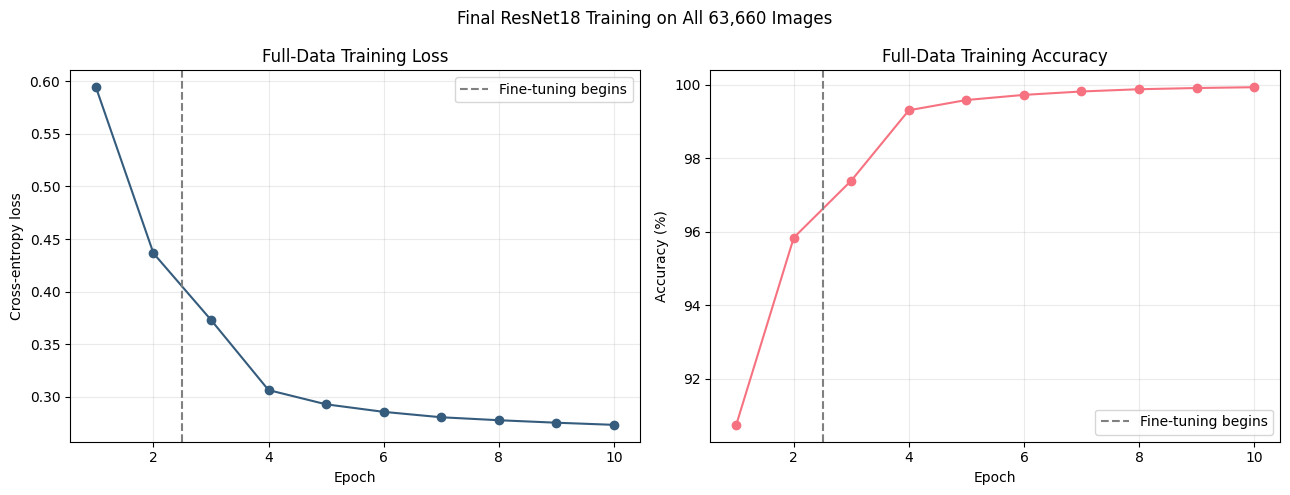

Saved: /kaggle/working/outputs/figures/figure_32_full_data_training_curves.png


In [25]:
# Plots training accuracy and loss without claiming validation results
if training_history is not None:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(
        training_history["epoch"],
        training_history["training_loss"],
        marker="o",
        color="#355C7D",
    )
    axes[0].set_title("Full-Data Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].grid(alpha=0.25)

    axes[1].plot(
        training_history["epoch"],
        training_history["training_accuracy"] * 100,
        marker="o",
        color="#F67280",
    )
    axes[1].set_title("Full-Data Training Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(alpha=0.25)

    for axis in axes:
        axis.axvline(
            HEAD_ONLY_EPOCHS + 0.5,
            linestyle="--",
            color="grey",
            label="Fine-tuning begins",
        )
        axis.legend()

    figure.suptitle("Final ResNet18 Training on All 63,660 Images")
    figure.tight_layout()
    # Saves the figure so it can be included in the report
    figure.savefig(CURVES_PATH, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", CURVES_PATH)
else:
    print("Training curves will be created after training.")

# Part C: Final Test Prediction

Prediction begins only after all ten epochs complete. The test loader remains deterministic and preserves sample order.

## 13. Reload and Verify the Final Checkpoint

In [26]:
# Reloads the completed model checkpoint when the schedule finishes
final_model = None
if RUN_TRAINING and training_information["completed_schedule"]:
    # Reads the saved checkpoint so training does not need to be repeated
    checkpoint = torch.load(
        FINAL_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
    if checkpoint["epoch"] != TOTAL_EPOCHS:
        raise RuntimeError("The final checkpoint is not from epoch 10.")
    if checkpoint["class_names"] != CLASS_NAMES:
        raise RuntimeError("Checkpoint class order is incorrect.")

    final_model = models.resnet18(weights=None)
    final_model.fc = nn.Linear(final_model.fc.in_features, NUMBER_OF_CLASSES)
    # Copies the saved weights into the matching model architecture
    final_model.load_state_dict(
        {
            key.removeprefix("module."): value
            for key, value in checkpoint["model_state_dict"].items()
        }
    )
    final_model = final_model.to(DEVICE)
    if DEVICE.type == "cuda":
        final_model = final_model.to(memory_format=torch.channels_last)
    if DEVICE.type == "cuda" and torch.cuda.device_count() > 1:
        final_model = nn.DataParallel(final_model)
    # Switches the model to evaluation behaviour for prediction
    final_model.eval()
    print("Final checkpoint verified: epoch", checkpoint["epoch"])
elif RUN_TRAINING:
    print(
        f"Training paused after epoch {training_information['epochs_completed']}. "
        "A recovery archive will be created below; no submission will be made."
    )
else:
    print("Final checkpoint verification is pending training.")

Final checkpoint verified: epoch 10


## 14. Generate Ordered Test Predictions

No TTA is applied because both controlled validation experiments showed no reliable accuracy improvement.

In [27]:
# Generates ordered test predictions using the completed model
prediction_table = None
submission = None

if final_model is not None:
    prediction_rows = []
    prediction_start = time.perf_counter()
    # Switches the model to evaluation behaviour for prediction
    final_model.eval()
    # Disables gradient tracking because this step does not train the model
    with torch.inference_mode():
        for batch in test_loader:
            images = batch["image"].to(DEVICE, non_blocking=PIN_MEMORY)
            if DEVICE.type == "cuda":
                images = images.contiguous(memory_format=torch.channels_last)
            with mixed_precision_context():
                logits = final_model(images)
            probabilities = torch.softmax(logits.float(), dim=1).cpu()
            confidence, predicted_indices = probabilities.max(dim=1)

            for image_id, row_index, predicted_index, score in zip(
                batch["image_id"],
                batch["row_index"].tolist(),
                predicted_indices.tolist(),
                confidence.tolist(),
            ):
                prediction_rows.append(
                    {
                        "row_index": row_index,
                        "image_id": str(image_id),
                        "predicted_index": predicted_index,
                        "class": INDEX_TO_CLASS[predicted_index],
                        "confidence": score,
                    }
                )

    prediction_table = pd.DataFrame(prediction_rows).sort_values("row_index")
    # Saves the table as a CSV file for later notebooks or report evidence
    prediction_table.to_csv(PREDICTIONS_PATH, index=False)

    submission = sample_submission[["image_id"]].copy()
    submission["class"] = prediction_table["class"].to_numpy()
    # Saves the table as a CSV file for later notebooks or report evidence
    submission.to_csv(SUBMISSION_PATH, index=False)

    print("Predictions:", f"{len(prediction_table):,}")
    print(
        "Prediction time:",
        f"{(time.perf_counter() - prediction_start) / 60:.2f} minutes",
    )
    display(submission.head())
else:
    print("Test prediction is pending final training.")

Predictions: 29,443
Prediction time: 24.67 minutes


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


## 15. Verify Submission and Plot Predicted Distribution

The hidden test labels are unavailable. This section checks structure and class validity only; it does not estimate test accuracy.

,check,result,expected
0,Final checkpoint exists,True,True
1,All ten epochs completed,True,True
2,"All 63,660 labels were used",True,True
3,"Submission has exactly 29,443 rows",True,True
4,Submission columns are image_id and class,True,True
5,Submission order matches sample_submission.csv,True,True
6,Every predicted class is valid,True,True
7,No prediction is missing,True,True
8,Submission CSV exists,True,True


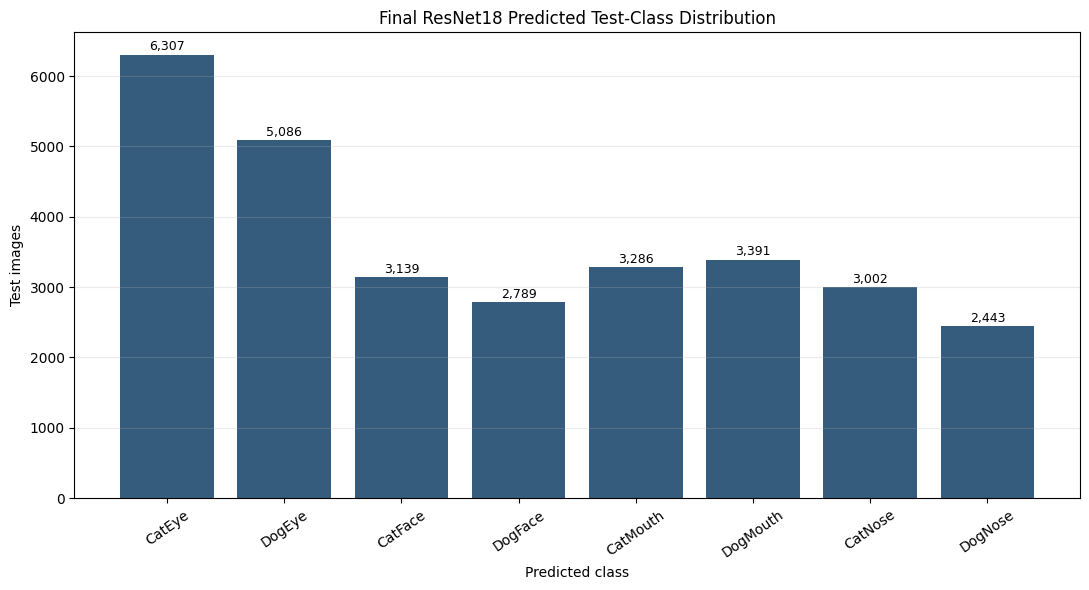

Saved: /kaggle/working/outputs/figures/figure_33_full_data_prediction_distribution.png


In [28]:
# Checks the submission structure and saves prediction evidence
if submission is not None:
    submission_checks = pd.DataFrame(
        {
            "check": [
                "Final checkpoint exists",
                "All ten epochs completed",
                "All 63,660 labels were used",
                "Submission has exactly 29,443 rows",
                "Submission columns are image_id and class",
                "Submission order matches sample_submission.csv",
                "Every predicted class is valid",
                "No prediction is missing",
                "Submission CSV exists",
            ],
            "result": [
                FINAL_CHECKPOINT_PATH.exists(),
                training_information["completed_schedule"],
                training_information["training_images"] == 63660,
                len(submission) == 29443,
                submission.columns.tolist() == ["image_id", "class"],
                submission["image_id"].astype("string").tolist()
                == sample_submission["image_id"].astype("string").tolist(),
                set(submission["class"]).issubset(set(CLASS_NAMES)),
                submission["class"].notna().all(),
                SUBMISSION_PATH.exists(),
            ],
            "expected": [True] * 9,
        }
    )
    # Saves the table as a CSV file for later notebooks or report evidence
    submission_checks.to_csv(CHECKS_PATH, index=False)
    display(submission_checks)
    assert submission_checks["result"].all()

    predicted_distribution = (
        submission["class"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )
    figure, axis = plt.subplots(figsize=(11, 6))
    bars = axis.bar(
        predicted_distribution.index,
        predicted_distribution.values,
        color="#355C7D",
    )
    for bar, value in zip(bars, predicted_distribution.values):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            value + max(predicted_distribution.values) * 0.01,
            f"{value:,}",
            ha="center",
            fontsize=9,
        )
    axis.set_title("Final ResNet18 Predicted Test-Class Distribution")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Test images")
    axis.tick_params(axis="x", rotation=35)
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    # Saves the figure so it can be included in the report
    figure.savefig(
        PREDICTION_DISTRIBUTION_PATH,
        dpi=220,
        bbox_inches="tight",
    )
    plt.show()
    print("Saved:", PREDICTION_DISTRIBUTION_PATH)
else:
    print("Submission verification is pending final training.")

## 16. Package the Final Model, Submission, and Evidence

Download this archive and the standalone submission before closing the Kaggle session.

In [29]:
# Packages completed results or partial progress for recovery
if submission is not None:
    result_files = [
        FINAL_CHECKPOINT_PATH,
        HISTORY_PATH,
        SUMMARY_PATH,
        CONFIG_PATH,
        CHECKS_PATH,
        PREDICTIONS_PATH,
        SUBMISSION_PATH,
        CURVES_PATH,
        PREDICTION_DISTRIBUTION_PATH,
    ]
    missing = [path for path in result_files if not path.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing final result files:\n"
            + "\n".join(str(path) for path in missing)
        )

    archive_path = PROJECT_ROOT / "final_resnet18_full_data_results.zip"
    with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
        for result_file in result_files:
            archive.write(
                result_file,
                arcname=result_file.relative_to(PROJECT_ROOT),
            )

    print("Final archive:", archive_path)
    print("Submission:", SUBMISSION_PATH)
    display(FileLink(str(archive_path)))
    display(FileLink(str(SUBMISSION_PATH)))
elif RUN_TRAINING and LATEST_CHECKPOINT_PATH.exists():
    recovery_files = [
        LATEST_CHECKPOINT_PATH,
        HISTORY_PATH,
        SUMMARY_PATH,
        CONFIG_PATH,
        CURVES_PATH,
    ]
    missing = [path for path in recovery_files if not path.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing recovery files:\n"
            + "\n".join(str(path) for path in missing)
        )

    recovery_path = (
        PROJECT_ROOT
        / f"final_resnet18_recovery_epoch_{training_information['epochs_completed']}.zip"
    )
    with ZipFile(recovery_path, "w", ZIP_DEFLATED) as archive:
        for recovery_file in recovery_files:
            archive.write(
                recovery_file,
                arcname=recovery_file.relative_to(PROJECT_ROOT),
            )

    print("Training is incomplete; no Kaggle submission was created.")
    print("Recovery archive:", recovery_path)
    display(FileLink(str(recovery_path)))
else:
    print("Final packaging is pending training and prediction.")

Final archive: /kaggle/working/final_resnet18_full_data_results.zip
Submission: /kaggle/working/submission_resnet18_full_data.csv


/kaggle/working/final_resnet18_full_data_results.zip

/kaggle/working/submission_resnet18_full_data.csv

## 17. Final Notebook Conclusion

In [30]:
# Displays the final run status and saved result locations
if submission is not None:
    display(
        Markdown(
            f"""
# Final Full-Data ResNet18 Completed

The final ResNet18 trained for **{training_information['epochs_completed']} epochs** using all **{training_information['training_images']:,} labelled images**. Final augmented-training accuracy was **{training_information['final_training_accuracy']:.2%}** and total training time was **{training_information['total_training_minutes']:.1f} minutes**.

The final submission contains **{len(submission):,} predictions** in the exact order of `sample_submission.csv`. Black square padding was retained, and no TTA or rejected geometry transformation was used. Kaggle test images were used only after the fixed training schedule completed.

Training accuracy is not an estimate of unseen-test accuracy. Generalisation evidence remains the earlier original and group-aware validation experiments; the Kaggle leaderboard score must be reported separately after submission.
"""
        )
    )
else:
    display(Markdown("# Final training and submission are pending."))


# Final Full-Data ResNet18 Completed

The final ResNet18 trained for **10 epochs** using all **63,660 labelled images**. Final augmented-training accuracy was **99.94%** and total training time was **91.7 minutes**.

The final submission contains **29,443 predictions** in the exact order of `sample_submission.csv`. Black square padding was retained, and no TTA or rejected geometry transformation was used. Kaggle test images were used only after the fixed training schedule completed.

Training accuracy is not an estimate of unseen-test accuracy. Generalisation evidence remains the earlier original and group-aware validation experiments; the Kaggle leaderboard score must be reported separately after submission.
